# ARM KAZR Cloud Persistence Project: Prediction Dataset Construction

**Alec Blevins — STA 496, Fall 2026**

## Purpose

In this notebook, we will run each /src module, considering each step's assumptions. This will motivate `build_dataset.py`, building our final prediction dataset. 
- **Sample:** We will use 3 to 5 days for a walkthrough, including edge cases. A full year run will follow. 

## Current Assumptions
| # | Assumption | Checked in |
|---|---|---|
| A1 | State comes from layer bases: any base >= 0 is cloudy, all bases == -1 is clear, anything else is unknown | §2 |
| A2 | Unknown states are never bridged or filled | §2, §5 |
| A3 | Days are concatenated before binning (midnight-safe) | §3 |
| A4 | 20 s bins start at 00:00:00 of each day, label = left edge | §4 |
| A5 | A bin is cloudy if >50% of its samples are cloudy and it is fully observed and known | §4 |
| A6 | Features use bins at or before t; the target uses bins after t | §6, §7 |
| A7 | A row is valid if the current bin is cloudy, the target is defined and the features are complete | §7 |
| A8 | Folds are chronological with an embargo of one horizon | §8 |


## 1. Imports & Paths

In [1]:
###################
##Library Imports##
###################

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

#Path to project root and interim data directory
_start = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in [_start, *_start.parents] if (c/"ARM_DATA"/"2024-2025").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))

####################
##Function Imports##
####################

from src.qc import apply_qc
from src.cloud_state import construct_cloud_state, concat_cloud_state_frames
from src.aggregation import aggregate_cloud_state
from src.targets import build_target, horizon_to_bins, chronological_split
from src.features import aggregate_structure, build_features, check_no_lookahead

#Interim data directory and configuration
INTERIM = PROJECT_ROOT/"ARM_DATA"/"2024-2025"/"interim"/"sgparsclkazr1kolliasC1.c0"

CONFIG = dict(interval="20s", horizon="20min", target_kind="persistence")
H = horizon_to_bins(CONFIG["horizon"], CONFIG["interval"])   # 60 bins

#Here, a helper function to load and process data for given dates into cloud state frames
def load_days(dates):
    """
    Open each interim file, apply QC in memory, build the 4 s state frame.
    """

    frames = []
    for d in dates:
        with xr.open_dataset(INTERIM/f"kazr_{d}.nc") as ds:
            frames.append(construct_cloud_state(apply_qc(ds)).drop(columns="cloud_state_label")) #Apply qc and construct cloud state
    return frames

print("H =", H, "bins")

H = 60 bins


## 1. Per-day cloud state cross-check (A1, A2)
Each interim file is opened, `apply_qc` runs in memory, and `construct_cloud_state` returns one row per 4s timestamp. 
Unknown (-1) menas neither "any base >= 0" nor "all bases == -1" held. 

In [2]:
VAL_DATES = ["20240101", "20240102", "20240103"] #The three daily files to cross-check against notebook 03
val_frames = load_days(VAL_DATES) #Load dates
f0 = val_frames[0]
display(f0.head())
print(f0.dtypes)

# A1 internal consistency
for d, f in zip(VAL_DATES, val_frames): #Check internal consistency for each date
    clear, cloudy = f.cloud_state == 0, f.cloud_state == 1 #Boolean masks for clear and cloudy states
    assert f.cloud_state.notna().all() #Ensure no missing cloud state values
    assert f.loc[clear, ["lowest_cloud_base_m", "highest_cloud_top_m"]].isna().all().all() #Clear sky should have no cloud base or top
    assert (f.loc[cloudy, "n_cloud_layers"] >= 1).all() #Cloudy sky should have at least one cloud layer
    assert (f.loc[clear, "n_cloud_layers"] == 0).all() #Clear sky should have zero cloud layers

# Cross-check against notebook 03
expected = {"20240101": (20820, 780, 0), "20240102": (20596, 1004, 0), "20240103": (3075, 18525, 0)}
for d, f in zip(VAL_DATES, val_frames):
    got = ((f.cloud_state == 1).sum(), (f.cloud_state == 0).sum(), (f.cloud_state == -1).sum())
    assert got == expected[d], (d, got)
print("[OK] matches notebook 03")

,cloud_state,n_cloud_layers,lowest_cloud_base_m,highest_cloud_top_m,kazr_available
time,,,,,
2024-01-01 00:00:00,0,0,NaN,NaN,True
2024-01-01 00:00:04,0,0,NaN,NaN,True
2024-01-01 00:00:08,1,3,400.0,7600.0,True
2024-01-01 00:00:12,1,3,400.0,8110.0,True
2024-01-01 00:00:16,1,3,400.0,8140.0,True


cloud_state               int8
n_cloud_layers            int8
lowest_cloud_base_m    float32
highest_cloud_top_m    float32
kazr_available            bool
dtype: object
[OK] matches notebook 03


## 2. Concatenate days before binning (A3)
Lagged features and feature targets must see across midnight. Binning and targets per day would lose or misclassify bins near the end of each day. 

Thus, we show the effect of this assumption.

In [3]:
frame4 = concat_cloud_state_frames(val_frames) #Concatenate all daily frames into a single frame
assert frame4.index.is_monotonic_increasing #Ensure the concatenated frame has a monotonically increasing index
assert (frame4.index.to_series().diff().dropna() == pd.Timedelta("4s")).all() #Ensure the time difference between consecutive rows is 4 seconds

# Rows around the first midnight
mid = pd.Timestamp("2024-01-02")
display(frame4.loc[mid - pd.Timedelta("12s"): mid + pd.Timedelta("8s"), ["cloud_state", "n_cloud_layers"]]) #Display rows around the first midnight

# Midnight bug demo: persistence target per day vs. on the concatenation
_, s_all = aggregate_cloud_state(frame4["cloud_state"], CONFIG["interval"]) #Aggregate cloud state for the concatenated frame
t_all = build_target(s_all, H, "persistence") #Build the persistence target for the concatenated frame

per_day_valid = 0
for f in val_frames:
    _, s_d = aggregate_cloud_state(f["cloud_state"], CONFIG["interval"]) #Aggregate cloud state for each daily frame
    per_day_valid += int(build_target(s_d, H, "persistence").target_valid.sum()) #Build the persistence target for each daily frame and count valid rows

print("valid rows, per day      :", per_day_valid)
print("valid rows, concatenated :", int(t_all.target_valid.sum()))
print("rows lost to the midnight bug:", int(t_all.target_valid.sum()) - per_day_valid)

,cloud_state,n_cloud_layers
time,,
2024-01-01 23:59:48,0,0
2024-01-01 23:59:52,0,0
2024-01-01 23:59:56,0,0
2024-01-02 00:00:00,0,0
2024-01-02 00:00:04,0,0
2024-01-02 00:00:08,0,0


valid rows, per day      : 8896
valid rows, concatenated : 8896
rows lost to the midnight bug: 0


## 3. Aggregation to 20s bin (A4, A5)

Bins start at 00:00:00 of each day and the timestamp is the left edge. 

In [4]:
bins, s20 = aggregate_cloud_state(frame4["cloud_state"], CONFIG["interval"]) #Aggregate cloud state for the full frame with the configured interval
assert len(bins) == len(VAL_DATES) * 4320  # Ensure the number of bins matches the expected count for the validation dates

# One bin in detail
t0 = pd.Timestamp("2024-01-01 00:00:00")
print(frame4.loc[t0: t0 + pd.Timedelta("19s"), "cloud_state"].to_string())  # Print cloud state for the first 20 seconds of 2024-01-01
print(bins.loc[t0], "-> bin state:", s20.loc[t0])  # Print the aggregated bin state for the first bin of 2024-01-01

# Composition
comp = pd.Series("mixed", index=bins.index)
comp[bins.cloud_fraction == 1] = "all cloudy"
comp[bins.cloud_fraction == 0] = "all clear"
comp[s20 == -1] = "unknown"
display(comp.value_counts())

# Toybox example, rule test on a synthetic series (8 s bins, 2 samples each)
idx = pd.date_range("2024-01-01", periods=8, freq="4s") #Generate a date range for the synthetic series with 4-second intervals
syn = pd.Series([1, 0, 1, 1, 1, -1, 0, 0], index=idx, dtype="int8") #Create a synthetic cloud state series
_, syn_state = aggregate_cloud_state(syn, "8s") #Aggregate the synthetic series into 8-second bins
assert syn_state.tolist() == [-1, 1, -1, 0]   # tie, cloudy, has-unknown, clear
print("[OK] tie and unknown rules")

time
2024-01-01 00:00:00    0
2024-01-01 00:00:04    0
2024-01-01 00:00:08    1
2024-01-01 00:00:12    1
2024-01-01 00:00:16    1
n_observed           5
n_known              5
n_cloudy             3
cloud_fraction     0.6
fully_observed    True
fully_known       True
Name: 2024-01-01 00:00:00, dtype: object -> bin state: 1


all cloudy    8871
all clear     4035
mixed           54
Name: count, dtype: int64

[OK] tie and unknown rules


## 3. Downtime days: what unknown looks like (A2)
Here, we will test a walkthrough example from 2024-02-01 to 2024-02-03. KAZR was only 67.7% available on 2024-02-02. 

The state product can still be known when KAZR is down (it uses MPL), so availability and state are kept as separate fields. 

cloud_state
Cloudy     52956
Clear       8261
Unknown     3583
Name: count, dtype: int64
unknown bins: 725 of 12960


bin_state,-1,0,1
kazr_avail_frac,,,
0.0,724,0,669
0.8,1,0,1
1.0,0,1655,9910


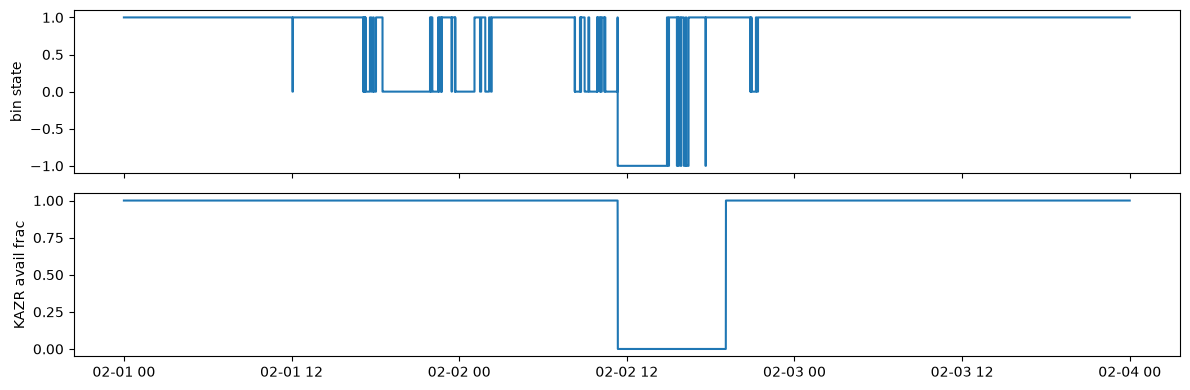

In [5]:
WALK_DATES = ["20240201", "20240202", "20240203"]
walk_frames = load_days(WALK_DATES) #Load days function
frame4 = concat_cloud_state_frames(walk_frames) #concatenate cloud state frames from all walk days
bins, s20 = aggregate_cloud_state(frame4["cloud_state"], CONFIG["interval"]) #aggregate cloud state into bins
structure = aggregate_structure(frame4, CONFIG["interval"]) #aggregate structure information into intervals

print(frame4.cloud_state.value_counts().rename({1: "Cloudy", 0: "Clear", -1: "Unknown"}))
print("unknown bins:", int((s20 == -1).sum()), "of", len(s20))
display(pd.crosstab(structure.kazr_avail_frac.round(1), s20.rename({1: "cloudy", 0: "clear", -1: "unknown"}) if False else s20)) #Do a cross-tabulation of KAZR availability fraction and cloud state bins

fig, ax = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
ax[0].step(s20.index, s20, where="post"); ax[0].set_ylabel("bin state")
ax[1].plot(structure.index, structure.kazr_avail_frac); ax[1].set_ylabel("KAZR avail frac")
plt.tight_layout(); plt.show()

## 5. Features and the leakage check (A6)
`build_features` uses only bins <= t. Rolling windows use `min_periods = n`, so a window containing any unknown bin gives NaN, and a feature is NaN until a full window exists. 

`features_valid` is True only if every feature is non-NaN. 

[OK] no lookahead
features: ['cloud_fraction', 'run_length_min', 'hour_sin', 'hour_cos', 'cf_mean_1min', 'cf_min_1min', 'cf_change_1min', 'n_flips_1min', 'cf_mean_5min', 'cf_min_5min', 'cf_change_5min', 'n_flips_5min', 'cf_mean_20min', 'cf_min_20min', 'cf_change_20min', 'n_flips_20min', 'n_layers_mean', 'lowest_base_m', 'highest_top_m', 'vertical_span_m', 'kazr_avail_frac', 'lowest_base_change_5min', 'highest_top_change_5min']


,nan_rate
highest_top_change_5min,0.2035
lowest_base_change_5min,0.2035
lowest_base_m,0.1796
highest_top_m,0.1796
vertical_span_m,0.1796
cf_min_20min,0.0806
cf_mean_20min,0.0806
cf_change_20min,0.0687
cf_mean_5min,0.0641
cf_min_5min,0.0641


first valid bin: 2024-02-01 00:20:00


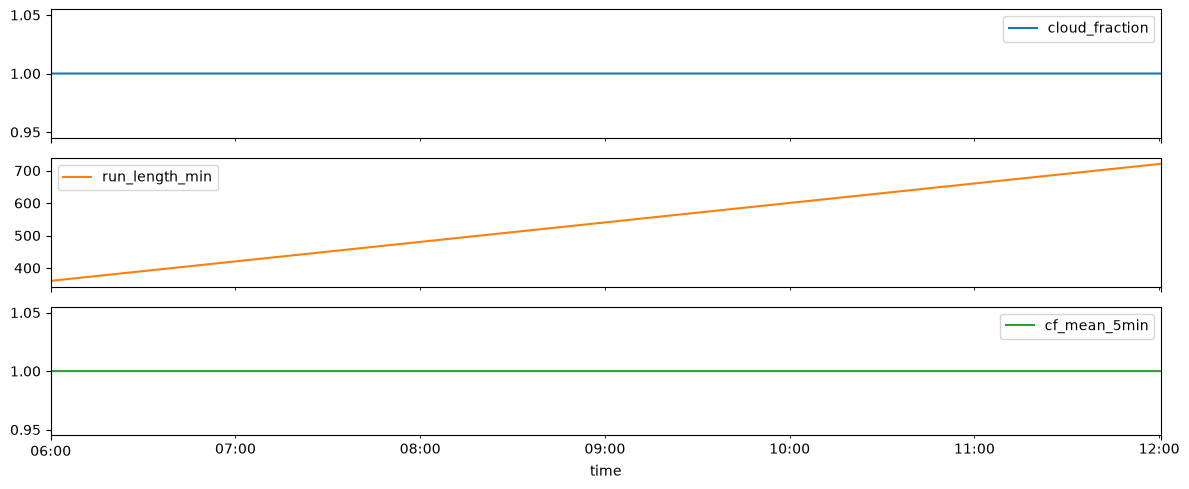

In [6]:
X = build_features(bins, s20, structure=structure) #Build features from cloud state bins and structure information
assert check_no_lookahead(bins, s20, "2024-02-02 12:00", structure=structure) #Call check function to ensure no lookahead in features
print("[OK] no lookahead")

print("features:", [c for c in X.columns if c != "features_valid"])
nan_rate = X.drop(columns="features_valid").isna().mean().sort_values(ascending=False) #Calculate the NaN rate for each feature column
display(nan_rate.round(4).to_frame("nan_rate"))
print("first valid bin:", X.index[X.features_valid.argmax()])   # about 20 min after start

X.loc["2024-02-01 06:00":"2024-02-01 12:00",
      ["cloud_fraction", "run_length_min", "cf_mean_5min"]].plot(subplots=True, figsize=(12, 5))
plt.tight_layout(); plt.show()

## 6. Join the target and validity masks (A7)
The feature window ends at bin t and the target window starts at t+1, so there is no overlap. A row is kept only if the current bin is cloudy, the target is defined, and all features are present. 

,n
all bins,12960
not currently cloudy,2380
"cloudy, target undefined",272
"cloudy, target ok, features incomplete",431
final rows,9877


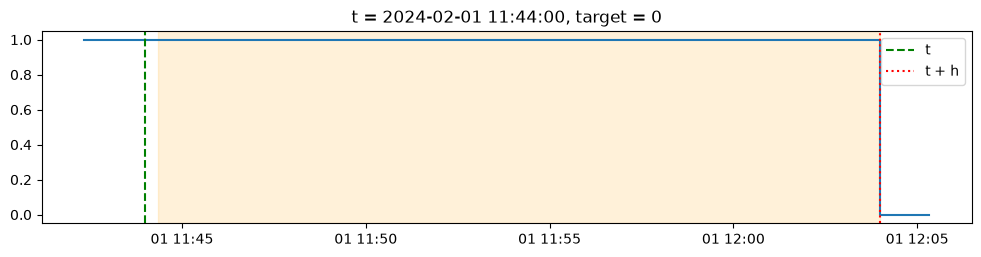

[OK] target alignment
rows kept without structure features: 10088 | with: 9877


In [7]:
T = build_target(s20, H, CONFIG["target_kind"]) #Build the target variable based on cloud state bins and the specified target kind
ds_ = X.join(T[["current_state", "target", "target_valid"]]) #Join features with target variables
ds_["row_ok"] = ds_.target_valid & ds_.features_valid #Mark rows where both target and features are valid

cloudy = ds_.current_state == 1 #Identify rows where the current state is cloudy
waterfall = pd.Series({ #Create a waterfall summary of the dataset based on cloud state and validity of target and features
    "all bins": len(ds_),
    "not currently cloudy": int((~cloudy).sum()),
    "cloudy, target undefined": int((cloudy & ~ds_.target_valid).sum()),
    "cloudy, target ok, features incomplete": int((cloudy & ds_.target_valid & ~ds_.features_valid).sum()),
    "final rows": int(ds_.row_ok.sum()),
})
display(waterfall.to_frame("n"))
assert waterfall["not currently cloudy"] + waterfall["cloudy, target undefined"] \
     + waterfall["cloudy, target ok, features incomplete"] + waterfall["final rows"] == len(ds_) #Ensure the sum of all categories equals the total number of rows

# Alignment on a real dissolution
ok = ds_[ds_.row_ok] #Select rows where both target and features are valid
ex = ok[ok.target == 0].index[0] #Select the first example where the target is 0
i = s20.index.get_loc(ex) #Get the location of this example in the s20 index
window = s20.iloc[i - 5: i + H + 5] #Define a window around this example for visualization

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.step(window.index, window, where="post")
ax.axvline(ex, color="g", ls="--", label="t")
ax.axvline(s20.index[i + H], color="r", ls=":", label="t + h")
ax.axvspan(s20.index[i + 1], s20.index[i + H], alpha=0.15, color="orange")
ax.legend(); ax.set_title(f"t = {ex}, target = 0"); plt.show()

# Target definition holds on valid rows
assert (ok.current_state == 1).all()
for t in ok[ok.target == 0].index[:200]: #Check that for each target 0 example, there is at least one 0 in the following H bins
    j = s20.index.get_loc(t)
    assert (s20.iloc[j + 1: j + H + 1] == 0).any()
for t in ok[ok.target == 1].index[:200]: #Check that for each target 1 example, all of the following H bins are 1
    j = s20.index.get_loc(t)
    assert (s20.iloc[j + 1: j + H + 1] == 1).all()
print("[OK] target alignment")

# Cost of structure features that are NaN after clear bins
X_no_struct = build_features(bins, s20)
print("rows kept without structure features:",
      int((T.target_valid & X_no_struct.features_valid).sum()),
      "| with:", int(ds_.row_ok.sum()))

## 7. Chronological splits with embargo (A8)
The bounds here are illustrative for a 3-day sample. The real split is decided on the full year (monthly persisted fraction ranges from 61% in October to 88% in January).

In [8]:
bounds = {"val_start": "2024-02-02 12:00", "test_start": "2024-02-03 00:00"}
masks = chronological_split(ds_.index, bounds, H, CONFIG["interval"]) #Split the dataset chronologically into train, val, and test folds
gap = pd.Timedelta(CONFIG["interval"]) * H  #Define the embargo gap to prevent target leakage across fold boundaries

ds_["fold"] = "embargo"  #Initialize all rows with the embargo label
for k, m in masks.items():  #Assign fold labels based on the masks
    ds_.loc[m, "fold"] = k #Assign the fold label to the rows specified by the mask

for k in ["train", "val", "test"]:
    v = ds_[(ds_.fold == k) & ds_.row_ok] #Select rows for the current fold that are valid
    print(f"{k:5s} n={len(v):6d}  {v.index.min()} -> {v.index.max()}  p_persisted={v.target.mean():.3f}") #Print summary statistics for the fold

# No target window crosses a fold boundary
vs, ts = pd.Timestamp(bounds["val_start"]), pd.Timestamp(bounds["test_start"])
assert (ds_[(ds_.fold == "train") & ds_.row_ok].index + gap < vs).all()
assert (ds_[(ds_.fold == "val") & ds_.row_ok].index + gap < ts).all()
print("[OK] embargo")

train n=  4542  2024-02-01 00:20:00 -> 2024-02-02 10:27:20  p_persisted=0.873
val   n=  1015  2024-02-02 16:44:40 -> 2024-02-02 23:39:40  p_persisted=0.937
test  n=  4260  2024-02-03 00:00:00 -> 2024-02-03 23:39:40  p_persisted=1.000
[OK] embargo


## 8. Output schema
| Group | Columns |
|---|---|
| Predictors | `cloud_fraction`, `run_length_min`, `hour_sin`, `hour_cos`, `cf_{mean,min,change}_{1min,5min,20min}`, `n_flips_{1min,5min,20min}`, `n_layers_mean`, `lowest_base_m`, `highest_top_m`, `vertical_span_m`, `kazr_avail_frac`, `lowest_base_change_5min`, `highest_top_change_5min` |
| Target | `target` (1 persisted, 0 dissolved) |
| Metadata | index = bin start time, `current_state`, `target_valid`, `features_valid`, `fold` |
| Not included | month, radar profile summaries (clutter and SNR will be decided later) |

In [9]:
final = ds_[ds_.row_ok].drop(columns=["row_ok", "target_valid", "features_valid"])  #Keep only the valid rows and drop auxiliary columns
print(final.shape, f"{final.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(final.dtypes)

(9877, 26) 2.2 MB
cloud_fraction             float64
run_length_min             float64
hour_sin                   float64
hour_cos                   float64
cf_mean_1min               float64
cf_min_1min                float64
cf_change_1min             float64
n_flips_1min               float64
cf_mean_5min               float64
cf_min_5min                float64
cf_change_5min             float64
n_flips_5min               float64
cf_mean_20min              float64
cf_min_20min               float64
cf_change_20min            float64
n_flips_20min              float64
n_layers_mean              float64
lowest_base_m              float32
highest_top_m              float32
vertical_span_m            float32
kazr_avail_frac            float64
lowest_base_change_5min    float32
highest_top_change_5min    float32
current_state                 int8
target                        int8
fold                           str
dtype: object


## 9. Full Year Scale
Here, we will run these same steps over all 366 days. This may be a highly expensive code cell. 

Sanity target from notebook 07: 

- 764,599 cloudy bins
- 79.2% persisted at 20 min before feature-validity filtering
- The difference between that and the final row count may be the cost of strict rolling windows and structure features

In [10]:
all_dates = sorted(p.stem.split("_")[1] for p in INTERIM.glob("kazr_2024*.nc"))  #Extract all dates from the filenames and sort them
assert len(all_dates) == 366  #Ensure that there are 366 days for the year 2024

frame_y = concat_cloud_state_frames(load_days(all_dates)) #Load and concatenate cloud state frames for all dates
bins_y, s_y = aggregate_cloud_state(frame_y["cloud_state"], CONFIG["interval"]) #Aggregate cloud state into bins based on the specified interval
X_y = build_features(bins_y, s_y, structure=aggregate_structure(frame_y, CONFIG["interval"])) #Build features for the aggregated bins
T_y = build_target(s_y, H, "persistence") #Build the target variable based on persistence over the horizon H
Y = X_y.join(T_y[["current_state", "target", "target_valid"]]) #Combine features and target into a single DataFrame
Y["row_ok"] = Y.target_valid & Y.features_valid #Mark rows that are valid for both features and target

print("cloudy bins        :", int((Y.current_state == 1).sum()))
print("target valid       :", int(Y.target_valid.sum()))
print("final rows         :", int(Y.row_ok.sum()))
print("rows lost to features:", int((Y.target_valid & ~Y.features_valid).sum()))
print("p_persisted (final):", round(Y.loc[Y.row_ok, "target"].mean(), 4))
display(Y[Y.row_ok].groupby(Y[Y.row_ok].index.month)["target"].agg(n="size", p_persisted="mean").round(3))

cloudy bins        : 764599
target valid       : 764267
final rows         : 716634
rows lost to features: 47633
p_persisted (final): 0.8305


,n,p_persisted
time,,
1,82831,0.901
2,66578,0.888
3,70702,0.869
4,59658,0.853
5,68036,0.824
6,75359,0.811
7,53068,0.744
8,56515,0.790
9,41052,0.777


## Conclusion